<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/statistical_physics/statphys_ch04_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Statistical Physics* — `statphys_ch04_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Statistical Physics — Chapter 4 Figures

Run in Google Colab. All figures saved to `figures/`.

| File | Slide |
|---|---|
| `fig_pV_paths.png` | §4.2 (path-dependence of work) |
| `fig_reversible_cycle.png` | §4.3 (reversible cycle) |
| `fig_carnot_cycle.png` | §4.3.1 (Carnot p-V and T-S planes) |
| `fig_carnot_efficiency.png` | §4.3.2 (efficiency vs $T_C/T_H$) |
| `fig_entropy_irreversible.png` | §4.3.3 (Clausius inequality) |
| `fig_thermodynamic_potentials.png` | §4.4 (Legendre chain) |
| `fig_third_law.png` | §4.5 (heat capacity → 0 as $T\to 0$) |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import os

os.makedirs('figures', exist_ok=True)

DARK_BG  = '#1a1a2e'
PANEL_BG = '#16213e'
BLUE     = '#7ec8e3'
YELLOW   = '#f9c74f'
GREEN    = '#90ee90'
RED      = '#e07070'
PURPLE   = '#b39ddb'
ORANGE   = '#ffb347'
DIM      = '#aaaaaa'

def base_style():
    plt.rcParams.update({
        'figure.facecolor': DARK_BG, 'axes.facecolor': PANEL_BG,
        'axes.edgecolor': DIM, 'axes.labelcolor': DIM,
        'axes.titlecolor': BLUE, 'xtick.color': DIM, 'ytick.color': DIM,
        'text.color': DIM, 'grid.color': '#2a2a4e', 'grid.linestyle': '--',
        'grid.alpha': 0.6, 'legend.facecolor': PANEL_BG, 'legend.edgecolor': DIM,
        'legend.labelcolor': DIM, 'font.family': 'sans-serif', 'font.size': 11,
        'axes.titlesize': 12, 'axes.labelsize': 11, 'legend.fontsize': 10,
        'lines.linewidth': 2.0, 'savefig.facecolor': DARK_BG, 'savefig.dpi': 180,
    })

base_style()
print('Ready.')


Ready.


## Fig 1 — Path-Dependence of Work in the p-V Plane

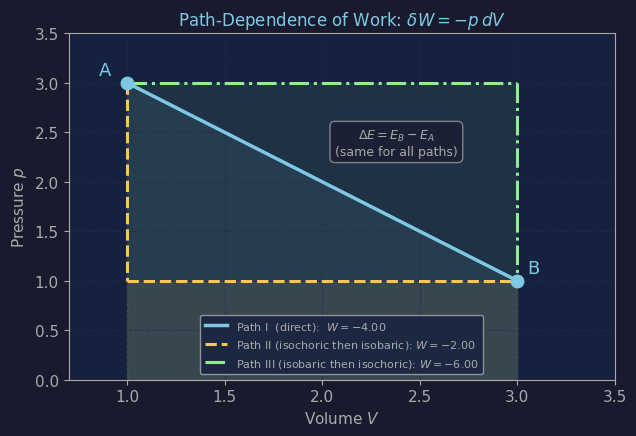

Saved.


In [2]:
base_style()

fig, ax = plt.subplots(figsize=(6.5, 4.5))

V1, V2 = 1.0, 3.0
p1, p2 = 3.0, 1.0

# Path I: isobaric expansion then isochoric compression
# A(V1,p1) -> B(V2,p1) -> C(V2,p2)
# But we want A->B with two different paths that have the SAME endpoints
# Let A = (V1,p1), B = (V2,p2)

# Path I: straight line in p-V
V_I = np.linspace(V1, V2, 300)
p_I = p1 + (p2 - p1) * (V_I - V1) / (V2 - V1)

# Path II: isochoric (V=V1, p: p1->p2) then isobaric (p=p2, V: V1->V2)
V_IIa = np.array([V1, V1]); p_IIa = np.array([p1, p2])
V_IIb = np.linspace(V1, V2, 200); p_IIb = np.ones_like(V_IIb) * p2

# Path III: isobaric (p=p1, V: V1->V2) then isochoric (V=V2, p: p1->p2)
V_IIIa = np.linspace(V1, V2, 200); p_IIIa = np.ones_like(V_IIIa) * p1
V_IIIb = np.array([V2, V2]); p_IIIb = np.array([p1, p2])

# Work = -integral p dV
W_I   = -np.trapezoid(p_I,   V_I)
W_II  = -np.trapezoid(p_IIb, V_IIb)   # isochoric part does no work
W_III = -np.trapezoid(p_IIIa, V_IIIa)

ax.plot(V_I,    p_I,    color=BLUE,   linewidth=2.5, label=f'Path I  (direct):  $W={W_I:.2f}$')
ax.plot(V_IIa,  p_IIa,  color=YELLOW, linewidth=2.2, linestyle='--')
ax.plot(V_IIb,  p_IIb,  color=YELLOW, linewidth=2.2, linestyle='--', label=f'Path II (isochoric then isobaric): $W={W_II:.2f}$')
ax.plot(V_IIIa, p_IIIa, color=GREEN,  linewidth=2.2, linestyle='-.')
ax.plot(V_IIIb, p_IIIb, color=GREEN,  linewidth=2.2, linestyle='-.', label=f'Path III (isobaric then isochoric): $W={W_III:.2f}$')

# Mark endpoints A and B
ax.plot(V1, p1, 'o', color=BLUE, markersize=9, zorder=5)
ax.plot(V2, p2, 'o', color=BLUE, markersize=9, zorder=5)
ax.text(V1 - 0.08, p1 + 0.08, 'A', color=BLUE, fontsize=13, ha='right')
ax.text(V2 + 0.05, p2 + 0.08, 'B', color=BLUE, fontsize=13)

# Shade work areas
ax.fill_between(V_I, 0, p_I, alpha=0.08, color=BLUE)
ax.fill_between(V_IIb, 0, p_IIb, alpha=0.08, color=YELLOW)
ax.fill_between(V_IIIa, 0, p_IIIa, alpha=0.08, color=GREEN)

ax.text(0.60, 0.65,
        r'$\Delta E = E_B - E_A$' + '\n(same for all paths)',
        transform=ax.transAxes, fontsize=9, color=DIM, ha='center',
        bbox=dict(boxstyle='round,pad=0.4', facecolor=DARK_BG, edgecolor=DIM, alpha=0.7))

ax.set_xlabel(r'Volume $V$')
ax.set_ylabel(r'Pressure $p$')
ax.set_title('Path-Dependence of Work: $\\delta W = -p\\,dV$')
ax.set_xlim(0.7, 3.5)
ax.set_ylim(0, 3.5)
ax.legend(loc='lower center', fontsize=8)
ax.grid(True)
fig.tight_layout()
fig.savefig('figures/fig_pV_paths.png')
plt.show(); print('Saved.')


## Fig 2 — Reversible Cycle in the p-V Plane

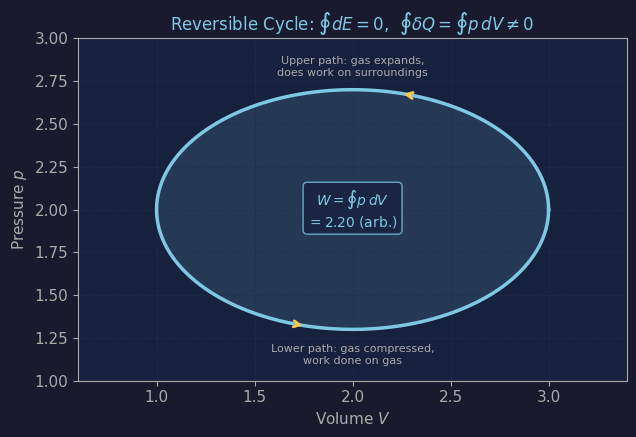

Saved.


In [3]:
base_style()

fig, ax = plt.subplots(figsize=(6.5, 4.5))

# Elliptical cycle: parametric
t = np.linspace(0, 2*np.pi, 500)
V_c = 2.0 + 1.0 * np.cos(t)
p_c = 2.0 + 0.7 * np.sin(t)

# Area = net work done
W_net = -np.trapezoid(p_c, V_c)

ax.fill(V_c, p_c, alpha=0.15, color=BLUE)
ax.plot(V_c, p_c, color=BLUE, linewidth=2.5)

# Arrow showing direction
i_arr = 100
ax.annotate('', xy=(V_c[i_arr+5], p_c[i_arr+5]),
            xytext=(V_c[i_arr], p_c[i_arr]),
            arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2.0))
i_arr2 = 350
ax.annotate('', xy=(V_c[i_arr2+5], p_c[i_arr2+5]),
            xytext=(V_c[i_arr2], p_c[i_arr2]),
            arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2.0))

ax.text(2.0, 2.0, f'$W = \\oint p\\,dV$\n$= {W_net:.2f}$ (arb.)',
        color=BLUE, fontsize=10, ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.3', facecolor=PANEL_BG, edgecolor=BLUE, alpha=0.8))

# Labels
ax.text(2.0, 2.78, 'Upper path: gas expands,\ndoes work on surroundings', color=DIM, fontsize=8, ha='center')
ax.text(2.0, 1.10, 'Lower path: gas compressed,\nwork done on gas', color=DIM, fontsize=8, ha='center')

ax.set_xlabel(r'Volume $V$')
ax.set_ylabel(r'Pressure $p$')
ax.set_title(r'Reversible Cycle: $\oint dE = 0$,  $\oint\delta Q = \oint p\,dV \neq 0$')
ax.set_xlim(0.6, 3.4)
ax.set_ylim(1.0, 3.0)
ax.grid(True)
fig.tight_layout()
fig.savefig('figures/fig_reversible_cycle.png')
plt.show(); print('Saved.')


## Fig 3 — Carnot Cycle (p-V and T-S planes)

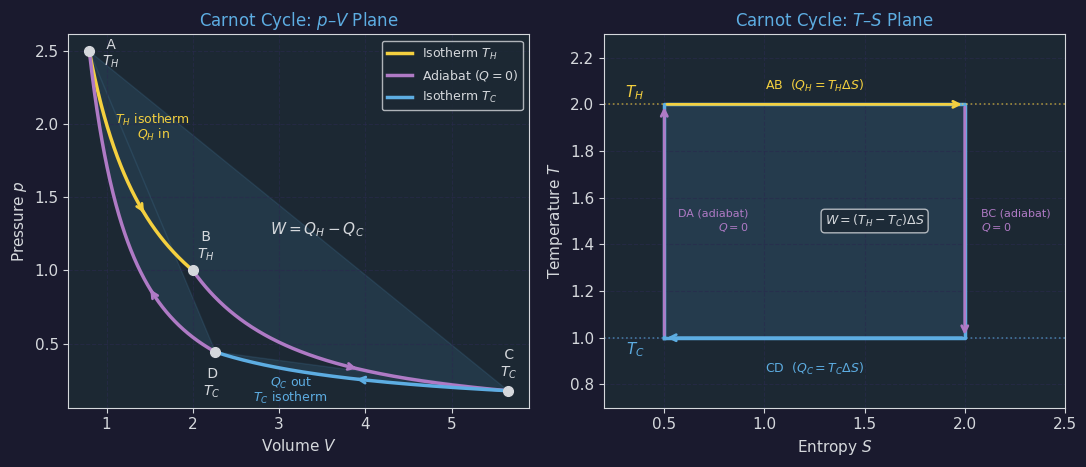

Saved.


In [4]:
# def base_style():
#     plt.style.use('dark_background')

BLUE   = '#5DADE2'
YELLOW = '#F4D03F'
PURPLE = '#AF7AC5'
DIM    = '#D5D8DC'
PANEL_BG = '#1C2833'

base_style()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

# =========================
# Left: p-V plane
# =========================
ax = axes[0]

gamma = 5/3
TH, TC = 2.0, 1.0
VA, VB = 0.8, 2.0

VC = VB * (TH/TC)**(1/(gamma-1))
VD = VA * (TH/TC)**(1/(gamma-1))

pA = TH/VA
pB = TH/VB
pC = TC/VC
pD = TC/VD

# Curves
V_AB = np.linspace(VA, VB, 300); p_AB = TH / V_AB
V_BC = np.linspace(VB, VC, 300); p_BC = pB * (VB / V_BC)**gamma
V_CD = np.linspace(VC, VD, 300); p_CD = TC / V_CD
V_DA = np.linspace(VD, VA, 300); p_DA = pD * (VD / V_DA)**gamma

# Fill cycle
V_fill = np.concatenate([V_AB, V_BC, V_CD[::-1], V_DA[::-1]])
p_fill = np.concatenate([p_AB, p_BC, p_CD[::-1], p_DA[::-1]])
ax.fill(V_fill, p_fill, alpha=0.12, color=BLUE)

# Plot lines
ax.plot(V_AB, p_AB, color=YELLOW, linewidth=2.5, label=r'Isotherm $T_H$')
ax.plot(V_BC, p_BC, color=PURPLE, linewidth=2.5, label=r'Adiabat ($Q=0$)')
ax.plot(V_CD[::-1], p_CD[::-1], color=BLUE, linewidth=2.5, label=r'Isotherm $T_C$')
ax.plot(V_DA[::-1], p_DA[::-1], color=PURPLE, linewidth=2.5)

# State points with temperature labels
points = [
    (VA, pA, ' A', r'$T_H$', 0.15,-0.10),
    (VB, pB, ' B', r'$T_H$', 0.05, 0.08),
    (VC, pC, ' C', r'$T_C$',-0.10, 0.10),
    (VD, pD, ' D', r'$T_C$',-0.15,-0.30)
]

for V_pt, p_pt, lbl, Tlbl, dx, dy in points:
    ax.plot(V_pt, p_pt, 'o', color=DIM, markersize=7, zorder=5)
    ax.text(V_pt + dx, p_pt + dy, f'{lbl}\n{Tlbl}', color=DIM, fontsize=10)

# Arrows (cycle direction)
i = 150
arrow_specs = [
    (V_AB, p_AB, YELLOW),
    (V_BC, p_BC, PURPLE),
    (V_CD, p_CD, BLUE),
    (V_DA, p_DA, PURPLE),
]

for arr_V, arr_p, col in arrow_specs:
    ax.annotate('', xy=(arr_V[i+8], arr_p[i+8]),
                xytext=(arr_V[i], arr_p[i]),
                arrowprops=dict(arrowstyle='->', color=col, lw=2.0))

# Labels
ax.text(1.1, 2.00, r'$T_H$ isotherm', color=YELLOW, fontsize=9)
ax.text(2.7, 0.10, r'$T_C$ isotherm', color=BLUE, fontsize=9)

ax.text(1.35, 1.90, r'$Q_H$ in', color=YELLOW, fontsize=9)
ax.text(2.9, 0.20, r'$Q_C$ out', color=BLUE, fontsize=9)
ax.text(2.9, 1.25, r'$W = Q_H - Q_C$', color=DIM, fontsize=11)

ax.set_xlabel(r'Volume $V$')
ax.set_ylabel(r'Pressure $p$')
ax.set_title(r'Carnot Cycle: $p$–$V$ Plane')
ax.legend(fontsize=9, loc='upper right')
ax.grid(True)

# =========================
# Right: T-S plane
# =========================
ax = axes[1]

S1, S2 = 0.5, 2.0

rect_S = [S1, S2, S2, S1, S1]
rect_T = [TC, TC, TH, TH, TC]

ax.fill(rect_S, rect_T, alpha=0.15, color=BLUE)
ax.plot(rect_S, rect_T, color=BLUE, linewidth=2.5)

# Cycle arrows (NEW)
arrow_TS = [
    ((S1, TH), (S2, TH), YELLOW),
    ((S2, TH), (S2, TC), PURPLE),
    ((S2, TC), (S1, TC), BLUE),
    ((S1, TC), (S1, TH), PURPLE),
]

for (x1, y1), (x2, y2), col in arrow_TS:
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=col, lw=2))

# Labels
ax.text((S1+S2)/2, TH+0.06, r'AB  ($Q_H = T_H\Delta S$)', color=YELLOW, fontsize=9, ha='center')
ax.text((S1+S2)/2, TC-0.1, r'CD  ($Q_C = T_C\Delta S$)', color=BLUE, fontsize=9, ha='center', va='top')

# Adiabats with Q=0
ax.text(S2+0.08, (TH+TC)/2, r'BC (adiabat)'+'\n'+r'$Q=0$', color=PURPLE, fontsize=8, va='center')
ax.text(S1+0.42, (TH+TC)/2, r'DA (adiabat)'+'\n'+r'$Q=0$', color=PURPLE, fontsize=8, va='center', ha='right')

# Work
ax.text((S1+S2)/2 +0.3, (TH+TC)/2, r'$W = (T_H - T_C)\Delta S$',
        color=DIM, fontsize=9, ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.3', facecolor=PANEL_BG, edgecolor=DIM, alpha=0.8))

# Temperature lines
ax.axhline(TH, color=YELLOW, linewidth=1.2, linestyle=':', alpha=0.6)
ax.axhline(TC, color=BLUE, linewidth=1.2, linestyle=':', alpha=0.6)

ax.text(0.4, TH +0.05, r'$T_H$', color=YELLOW, fontsize=11, ha='right', va='center')
ax.text(0.4, TC -0.05, r'$T_C$', color=BLUE, fontsize=11, ha='right', va='center')

ax.set_xlabel(r'Entropy $S$')
ax.set_ylabel(r'Temperature $T$')
ax.set_title(r'Carnot Cycle: $T$–$S$ Plane')

ax.set_xlim(S1-0.3, S2+0.5)
ax.set_ylim(TC-0.3, TH+0.3)
ax.grid(True)

# =========================
# Finalize
# =========================
fig.tight_layout()
fig.savefig('figures/fig_carnot_cycle.png', dpi=150)
plt.show()

print('Saved.')

## Fig 4 — Carnot Efficiency

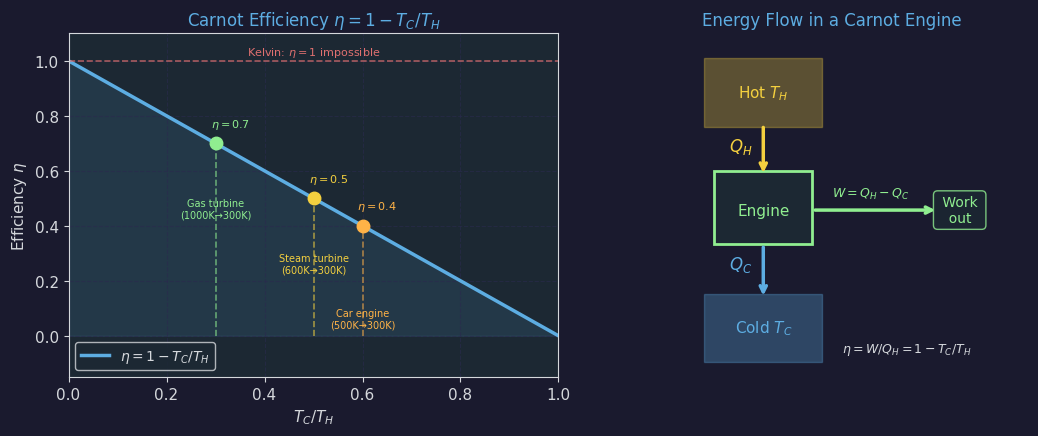

Saved.


In [5]:
base_style()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left: efficiency vs TC/TH
ax = axes[0]
x = np.linspace(0, 1, 300)  # TC/TH
eta = 1 - x

ax.plot(x, eta, color=BLUE, linewidth=2.5, label=r'$\eta = 1 - T_C/T_H$')
ax.fill_between(x, 0, eta, alpha=0.12, color=BLUE)

# Mark some practical examples
examples = [
    (300/600, 'Steam turbine\n(600K→300K)', 0.3),
    (300/1000, 'Gas turbine\n(1000K→300K)', 0.5),
    (300/500, 'Car engine\n(500K→300K)', 0.1),
]
colors_ex = [YELLOW, GREEN, ORANGE]
for (x0, label, y0), col in zip(examples, colors_ex):
    eta0 = 1 - x0
    ax.plot(x0, eta0, 'o', color=col, markersize=9, zorder=5)
    ax.vlines(x0, 0, eta0, colors=col, linewidth=1.2, linestyles='--', alpha=0.6)
    ax.text(x0 +0.03, eta0+0.06, f'$\\eta={eta0:.1f}$', color=col, fontsize=8, ha='center')
    ax.text(x0, y0, label, color=col, fontsize=7, ha='center', va='top')

ax.axhline(1.0, color=RED, linestyle='--', linewidth=1.2, alpha=0.7)
ax.text(0.5, 1.02, 'Kelvin: $\\eta=1$ impossible', color=RED, fontsize=8, ha='center')
ax.set_xlabel(r'$T_C / T_H$')
ax.set_ylabel(r'Efficiency $\eta$')
ax.set_title(r'Carnot Efficiency $\eta = 1 - T_C/T_H$')
ax.set_xlim(0, 1)
ax.set_ylim(-0.15, 1.1)
ax.legend()
ax.grid(True)

# Right: sankey-style energy flow
ax = axes[1]
ax.set_aspect('equal')
ax.set_xlim(-0.5, 3.5)
#ax.set_ylim(-0.5, 3.5)
ax.set_ylim(-0.5, 3.0)
ax.axis('off')
ax.set_title('Energy Flow in a Carnot Engine', color=BLUE)

# Hot reservoir
rect_H = plt.Rectangle((0.2, 2.05), 1.2, 0.7, facecolor=YELLOW, alpha=0.3, edgecolor=YELLOW)
ax.add_patch(rect_H)
ax.text(0.8, 2.40, r'Hot $T_H$', color=YELLOW, fontsize=11, ha='center', va='center')

# Cold reservoir
rect_C = plt.Rectangle((0.2, -0.35), 1.2, 0.7, facecolor=BLUE, alpha=0.3, edgecolor=BLUE)
ax.add_patch(rect_C)
ax.text(0.8, 0.00, r'Cold $T_C$', color=BLUE, fontsize=11, ha='center', va='center')

# Engine box
rect_E = plt.Rectangle((0.3, 0.85), 1.0, 0.75, facecolor=PANEL_BG, edgecolor=GREEN, linewidth=2)
ax.add_patch(rect_E)
ax.text(0.8, 1.20, 'Engine', color=GREEN, fontsize=11, ha='center', va='center')

# Arrows
ax.annotate('', xy=(0.8, 1.55), xytext=(0.8, 2.07),
            arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2.5))
ax.text(0.45, 1.80, r'$Q_H$', color=YELLOW, fontsize=12)

ax.annotate('', xy=(0.8, 0.30), xytext=(0.8, 0.85),
            arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5))
ax.text(0.45, 0.60, r'$Q_C$', color=BLUE, fontsize=12)

ax.annotate('', xy=(2.58, 1.20), xytext=(1.3, 1.20),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.5))
ax.text(1.5, 1.33, r'$W = Q_H - Q_C$', color=GREEN, fontsize=9)

ax.text(2.8, 1.20, ' Work \n  out  ', color=GREEN, fontsize=10, ha='center', va='center',
        bbox=dict(boxstyle='round', facecolor=PANEL_BG, edgecolor=GREEN, alpha=0.8))

ax.text(1.6, -0.25, r'$\eta = W/Q_H = 1 - T_C/T_H$', color=DIM, fontsize=9)

fig.tight_layout()
fig.savefig('figures/fig_carnot_efficiency.png')
plt.show(); print('Saved.')


## Fig 5 — Clausius Inequality and Entropy

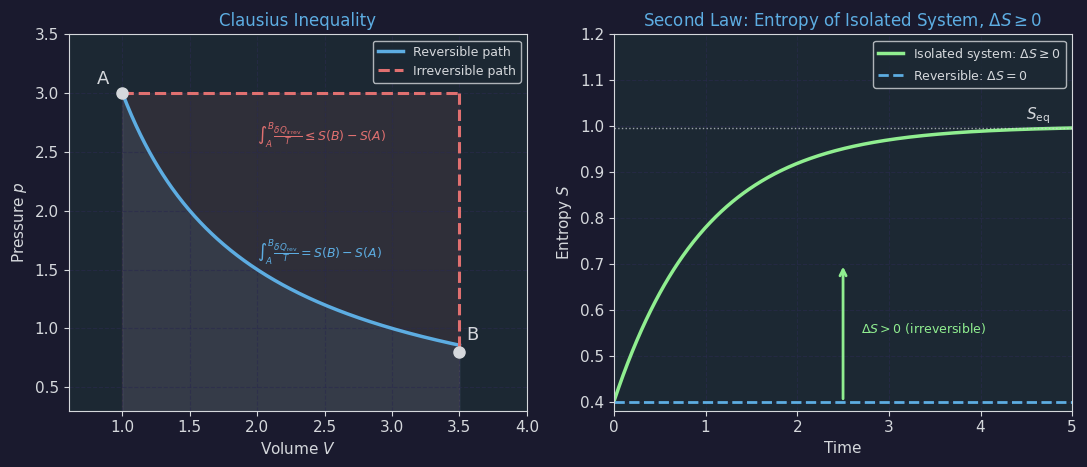

Saved.


In [6]:
base_style()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

# Left: delta_Q/T integral for reversible vs irreversible
ax = axes[0]

# Two paths from A to B in p-V
V1, V2 = 1.0, 3.5
p1, p2 = 3.0, 0.8

# Reversible (smooth curve)
V_rev = np.linspace(V1, V2, 300)
# Isothermal-like: p*V = const
c_rev = p1*V1
p_rev = c_rev / V_rev

# Irreversible (step function - sudden expansion then slow)
V_irr1 = np.array([V1, V2]); p_irr1 = np.array([p1, p1])
V_irr2 = np.array([V2, V2]); p_irr2 = np.array([p1, p2])

ax.plot(V_rev, p_rev, color=BLUE, linewidth=2.5, label='Reversible path')
ax.plot(V_irr1, p_irr1, color=RED, linewidth=2.2, linestyle='--')
ax.plot(V_irr2, p_irr2, color=RED, linewidth=2.2, linestyle='--', label='Irreversible path')

ax.plot(V1, p1, 'o', color=DIM, markersize=8, zorder=5)
ax.plot(V2, p2, 'o', color=DIM, markersize=8, zorder=5)
ax.text(V1-0.1, p1+0.08, 'A', color=DIM, fontsize=13, ha='right')
ax.text(V2+0.05, p2+0.1, 'B', color=DIM, fontsize=13)

ax.fill_between(V_rev, 0, p_rev, alpha=0.1, color=BLUE)
ax.fill_between(V_irr1, 0, p_irr1, alpha=0.1, color=RED)

ax.text(2.0, 1.6, r'$\int_A^B \frac{\delta Q_{\rm rev}}{T} = S(B)-S(A)$', color=BLUE, fontsize=9)
ax.text(2.0, 2.6, r'$\int_A^B \frac{\delta Q_{\rm irrev}}{T} \leq S(B)-S(A)$', color=RED, fontsize=9)

ax.set_xlabel(r'Volume $V$')
ax.set_ylabel(r'Pressure $p$')
ax.set_title('Clausius Inequality')
ax.legend(fontsize=9)
ax.grid(True)
ax.set_xlim(0.6, 4.0)
ax.set_ylim(0.3, 3.5)

# Right: entropy of an isolated system — monotonically non-decreasing
ax = axes[1]

# Schematic: irreversible process increasing S
t_eq = np.linspace(0, 5, 500)
S_eq = 1.0 - 0.6*np.exp(-t_eq)  # relaxes upward

ax.plot(t_eq, S_eq, color=GREEN, linewidth=2.5, label=r'Isolated system: $\Delta S \geq 0$')
ax.axhline(S_eq[-1], color=DIM, linestyle=':', linewidth=1.0, alpha=0.7)
ax.text(4.5, S_eq[-1]+0.02, r'$S_{\rm eq}$', color=DIM, fontsize=11)

# Annotate the increase
ax.annotate('', xy=(2.5, 0.70), xytext=(2.5, 0.40),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.0))
ax.text(2.7, 0.55, r'$\Delta S > 0$'+' (irreversible)', color=GREEN, fontsize=9)

# Show that reversible processes stay at same S
t_rev = np.array([0, 5]); S_rev = np.array([0.4, 0.4])
ax.plot(t_rev, S_rev, color=BLUE, linewidth=2.0, linestyle='--', label=r'Reversible: $\Delta S = 0$')

ax.set_xlabel(r'Time')
ax.set_ylabel(r'Entropy $S$')
ax.set_title(r'Second Law: Entropy of Isolated System, $\Delta S \geq 0$')
ax.set_xlim(0, 5)
ax.set_ylim(0.38, 1.2)
ax.legend(fontsize=9)
ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_entropy_irreversible.png')
plt.show(); print('Saved.')


## Fig 6 — Thermodynamic Potentials (Legendre Chain)

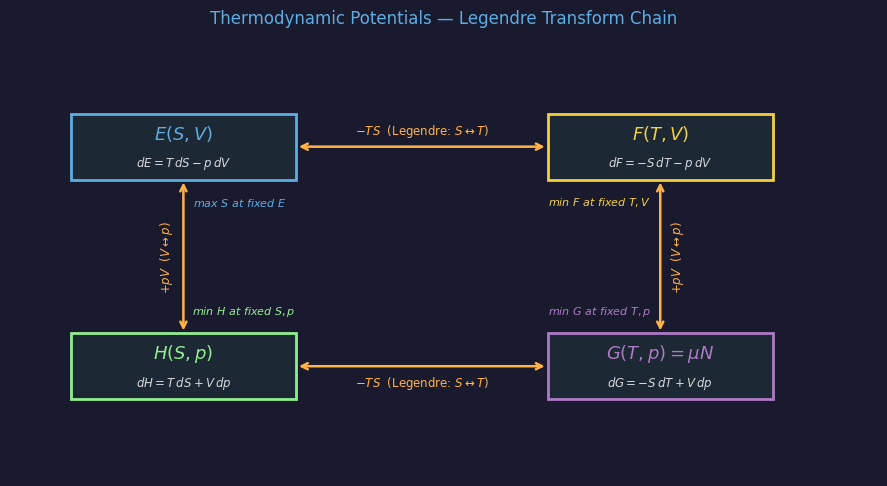

Saved.


In [7]:
base_style()

fig, ax = plt.subplots(figsize=(9, 5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis('off')
ax.set_facecolor(DARK_BG)
fig.patch.set_facecolor(DARK_BG)

# Box positions (x_centre, y_centre)
boxes = {
    'E': (2.0, 4.5, r'$E(S,V)$',       r'$dE = T\,dS - p\,dV$',         BLUE),
    'F': (7.5, 4.5, r'$F(T,V)$',       r'$dF = -S\,dT - p\,dV$',        YELLOW),
    'H': (2.0, 1.5, r'$H(S,p)$',       r'$dH = T\,dS + V\,dp$',          GREEN),
    'G': (7.5, 1.5, r'$G(T,p) = \mu N$', r'$dG = -S\,dT + V\,dp$',     PURPLE),
}

bw, bh = 2.6, 0.9
for key, (xc, yc, name, diff, col) in boxes.items():
    rect = plt.Rectangle((xc - bw/2, yc - bh/2), bw, bh,
                         facecolor=PANEL_BG, edgecolor=col, linewidth=2, zorder=2)
    ax.add_patch(rect)
    ax.text(xc, yc + 0.18, name, color=col, fontsize=13, ha='center', va='center', fontweight='bold', zorder=3)
    ax.text(xc, yc - 0.22, diff, color=DIM, fontsize=8.5, ha='center', va='center', zorder=3)

# Arrows with labels
arrow_kw = dict(arrowstyle='<->', color=DIM, lw=1.8)
transforms = [
    (2.0+bw/2, 4.5, 7.5-bw/2, 4.5, 'top',    r'$-TS$  (Legendre: $S\leftrightarrow T$)', 5.1),
    (2.0+bw/2, 1.5, 7.5-bw/2, 1.5, 'bottom',  r'$-TS$  (Legendre: $S\leftrightarrow T$)', 0.85),
    (2.0, 4.5-bh/2, 2.0, 1.5+bh/2, 'left',   r'$+pV$  ($V\leftrightarrow p$)', 0.5),
    (7.5, 4.5-bh/2, 7.5, 1.5+bh/2, 'right',  r'$+pV$  ($V\leftrightarrow p$)', 9.3),
]
for x1, y1, x2, y2, side, label, lx in transforms:
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='<->', color=ORANGE, lw=1.8))
    lmid_y = (y1+y2)/2
    lmid_x = (x1+x2)/2
    if side in ('top', 'bottom'):
        off = 0.22 if side == 'top' else -0.22
        ax.text(lmid_x, lmid_y+off, label, color=ORANGE, fontsize=8.5, ha='center', va='center')
    else:
        off = -0.2 if side == 'left' else 0.2
        ax.text(lmid_x+off, lmid_y, label, color=ORANGE, fontsize=8.5, ha='center', va='center', rotation=90)

# Natural minimisation conditions
conditions = [
    (2.65, 3.75, 'max $S$ at fixed $E$', BLUE),
    (6.8, 3.75,  'min $F$ at fixed $T,V$', YELLOW),
    (2.7, 2.25,  'min $H$ at fixed $S,p$', GREEN),
    (6.8, 2.25,  'min $G$ at fixed $T,p$', PURPLE),
]
for xc, yc, txt, col in conditions:
    ax.text(xc, yc, txt, color=col, fontsize=8, ha='center', va='center', style='italic')

ax.set_title('Thermodynamic Potentials — Legendre Transform Chain', color=BLUE, fontsize=12, pad=10)

fig.tight_layout()
fig.savefig('figures/fig_thermodynamic_potentials.png')
plt.show(); print('Saved.')


## Fig 7 — Third Law: Heat Capacities Vanish as T→0

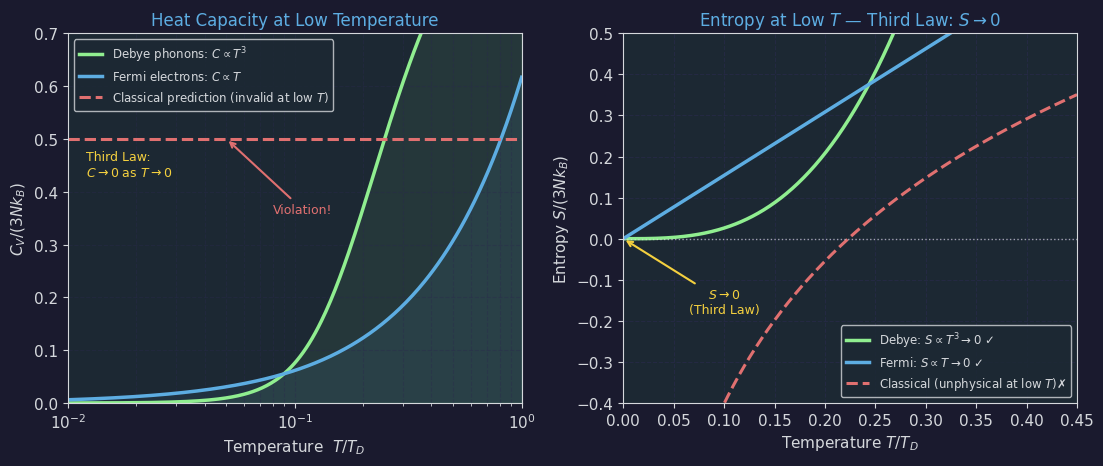

Saved.


In [8]:
from scipy.integrate import quad
base_style()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

# ── Left: C(T) ─────────────────────────────────────────────────────────
ax = axes[0]

# T in units of T_D.  Educational ratio T_F/T_D = r
r = 8.0  # T_F / T_D — chosen so both curves are visible
T = np.logspace(-2, 0, 300)  # T/T_D from 0.01 to 1.0

def debye_CV(T_over_TD):
    result = []
    for t in T_over_TD:
        xD = 1.0/t
        val, _ = quad(lambda x: x**4*np.exp(x)/(np.exp(x)-1)**2, 1e-8, xD)
        result.append(3*t**3*val)
    return np.array(result)

CV_debye   = debye_CV(T)            # C_V / (3Nk_B)
CV_fermi   = (np.pi**2/2/r) * T     # C_V / (3Nk_B), Fermi gas scaled by r
CV_classical = np.ones_like(T) * 0.5  # 3/2 Nk_B / (3Nk_B) = 1/2

ax.plot(T, CV_debye,    color=GREEN,  linewidth=2.5, label=r'Debye phonons: $C\propto T^3$')
ax.plot(T, CV_fermi,    color=BLUE,   linewidth=2.5, label=r'Fermi electrons: $C\propto T$')
ax.plot(T, CV_classical,color=RED,    linewidth=2.2, linestyle='--',
        label=r'Classical prediction (invalid at low $T$)')

ax.fill_between(T, 0, CV_debye, alpha=0.08, color=GREEN)
ax.fill_between(T, 0, CV_fermi, alpha=0.08, color=BLUE)

ax.text(0.012, 0.46, 'Third Law:', color=YELLOW, fontsize=9)
ax.text(0.012, 0.43, r'$C\to 0$ as $T\to 0$', color=YELLOW, fontsize=9)

ax.annotate('Violation!', xy=(0.05, 0.5), xytext=(0.08, 0.36),
            arrowprops=dict(arrowstyle='->', color=RED, lw=1.5),
            color=RED, fontsize=9)

ax.set_xscale('log')
ax.set_xlabel(r'Temperature  $T / T_D$')
ax.set_ylabel(r'$C_V / (3Nk_B)$')
ax.set_title('Heat Capacity at Low Temperature')
ax.set_xlim(T[0], T[-1])
ax.set_ylim(0, 0.7)
ax.legend(fontsize=8.5, loc='upper left')
ax.grid(True, which='both', alpha=0.4)

# ── Right: S(T) ────────────────────────────────────────────────────────
ax = axes[1]

# T range: 0 to 0.5 T_D (low-T regime only, T^3 law valid)
T2 = np.linspace(1e-3, 0.45, 400)

# S = integral_0^T C/T' dT'
# Debye (T << T_D): C/(3Nk_B) = (4pi^4/5)*t^3  =>  S/(3Nk_B) = (4pi^4/15)*t^3
S_debye = (4*np.pi**4/15) * T2**3

# Fermi: C/(3Nk_B) = (pi^2/2/r)*t  =>  S/(3Nk_B) = (pi^2/2/r)*t
# Use scale_F > 1 so that S_Fermi > S_Debye over the plot range
# (slope of T line > slope of T^3 for small T)
# With r=8: pi^2/(2*8) ≈ 0.617 > (4pi^4/15)*T^2 for T < sqrt(0.617/(4pi^4/15)) ≈ 0.154
# To keep Fermi > Debye up to T=0.45: use scale_F = 2.5/r
scale_F = 2.5
S_fermi = (np.pi**2/2/r) * scale_F * T2

# Classical: S ~ (3/2)*ln(T) + const — diverges to -inf as T->0
T_cl = T2[T2 > 0.08]  # start where S_cl enters ylim
S_cl = 0.5 * np.log(T_cl) + 0.75  # (1/2)*ln(T) + const in 3Nk_B units

ax.plot(T2, S_debye, color=GREEN, linewidth=2.5, label=r'Debye: $S\propto T^3\to 0$ ✓')
ax.plot(T2, S_fermi, color=BLUE,  linewidth=2.5, label=r'Fermi: $S\propto T\to 0$ ✓')
ax.plot(T_cl, S_cl,  color=RED,   linewidth=2.2, linestyle='--',
        label=r'Classical (unphysical at low $T$)✗')

ax.axhline(0, color=DIM, linewidth=1.0, linestyle=':', alpha=0.7)

ax.annotate(r'$S\to 0$' + '\n(Third Law)',
            xy=(0.00, 0.00), xytext=(0.10, -0.18),
            arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.5),
            color=YELLOW, fontsize=9, ha='center')

ax.set_xlabel(r'Temperature $T / T_D$')
ax.set_ylabel(r'Entropy $S / (3Nk_B)$')
ax.set_title(r'Entropy at Low $T$ — Third Law: $S\to 0$')
ax.set_xlim(0, 0.45)
ax.set_ylim(-0.4, 0.5)
ax.legend(fontsize=8.5)
ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_third_law.png')
plt.show(); print('Saved.')

## Summary

All figures saved to `./figures/`.

Copy the `figures/` folder next to `statphys_ch04_slides.qmd` and render:
```bash
quarto render statphys_ch04_slides.qmd
```

In [9]:
# ── Download all figures as a zip file (Colab) ──────────────────────────────
import zipfile
import os

zip_path = 'statphys_ch04_figures.zip'

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir('figures')):
        if fname.endswith('.png'):
            fpath = os.path.join('figures', fname)
            zf.write(fpath, fname)  # store without 'figures/' prefix
            print(f'  Added: {fname}')

print(f'\nZip created: {zip_path}')
print(f'Size: {os.path.getsize(zip_path) / 1024:.1f} KB')

# Download in Google Colab
try:
    from google.colab import files
    files.download(zip_path)
    print('Download started!')
except ImportError:
    print(f'Not running in Colab — file saved locally as: {zip_path}')


  Added: fig_carnot_cycle.png
  Added: fig_carnot_efficiency.png
  Added: fig_entropy_irreversible.png
  Added: fig_pV_paths.png
  Added: fig_reversible_cycle.png
  Added: fig_thermodynamic_potentials.png
  Added: fig_third_law.png

Zip created: statphys_ch04_figures.zip
Size: 763.9 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started!
